# Week 8: K-Nearest Neighbors with Different Distance Metrics
**Capstone project:** Predicting Health Risk and Diabetes Status from Lifestyle and Survey Data | Komal Misra

KNN makes a prediction for a new sample by finding the *k* most similar samples in the training data and taking a majority vote (classification) or an average (regression). The model is only as good as its definition of "similar," so this notebook tests that definition on both project datasets:

- **Dataset B:** CDC BRFSS 2015 diabetes indicators (253,680 rows, 21 survey features). Diabetes and prediabetes are collapsed into one positive class.
- **Dataset A:** Health & Lifestyle dataset (100,000 rows; demographics, behaviors, vitals). Targets are `disease_risk` and BMI.

**Sections**
1. Setup and data
2. How KNN predicts: one patient and their nearest neighbors
3. Euclidean vs. Manhattan distance
4. Feature scaling
5. Minkowski distance: tuning *p*
6. Cosine distance
7. Choosing *k* and checking for overfitting
8. Final model on the test set
9. Dataset A
10. Summary

## 1. Setup and data

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score,
                             accuracy_score, precision_recall_curve, mean_squared_error)

warnings.filterwarnings('ignore', message='Mind that for 0 < p < 1')
SEED = 42
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3})
COLORS = {'euclidean': '#2a78d6', 'manhattan': '#eb6834', 'cosine': '#1baf7a', 'chebyshev': '#6250d6'}

In [2]:
brfss = pd.read_csv('diabetes_012_health_indicators_BRFSS2015.csv')
life = pd.read_csv('health_lifestyle_dataset.csv')
print('BRFSS:', brfss.shape, '| Lifestyle:', life.shape)

brfss['diabetes'] = (brfss['Diabetes_012'] > 0).astype(int)
print(f"Diabetes/prediabetes prevalence: {brfss['diabetes'].mean():.1%}")
print('Exact duplicate rows in BRFSS:', brfss.duplicated().sum())

BRFSS: (253680, 22) | Lifestyle: (100000, 16)
Diabetes/prediabetes prevalence: 15.8%
Exact duplicate rows in BRFSS: 23899


KNN compares every test point with every training point, so it is slow on large data. As in earlier weeks, I use a **50,000-row stratified sample** of BRFSS with an **80/20 stratified train/test split** (seed 42). The 10,000-row test set is not touched until Section 8. For the cross-validated comparisons in Sections 3–7, I use a 15,000-row slice of the training set to keep run time reasonable.

In [3]:
X_all = brfss.drop(columns=['Diabetes_012', 'diabetes'])
y_all = brfss['diabetes']
X, _, y, _ = train_test_split(X_all, y_all, train_size=50_000, stratify=y_all, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_cv, _, y_cv, _ = train_test_split(X_train, y_train, train_size=15_000, stratify=y_train, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print('train', X_train.shape, '| test', X_test.shape, '| CV slice', X_cv.shape)

train (40000, 21) | test (10000, 21) | CV slice (15000, 21)


**Metric.** Only 15.8% of respondents are positive, so accuracy is misleading: predicting "no diabetes" for everyone already scores about 84%. I compare models by **ROC AUC**, which measures how well the predicted probability (the share of the *k* neighbors that are diabetic) ranks positives above negatives, without needing a cutoff. I choose a cutoff separately in Section 8.

In [4]:
def cv_auc(model, X=X_cv, y=y_cv):
    s = cross_val_score(model, X, y, cv=cv, scoring='roc_auc', n_jobs=-1)
    return s.mean(), s.std()

def knn(k=51, metric='euclidean', p=2, scale=True, **kw):
    algo = 'brute' if metric in ('cosine',) or (metric == 'minkowski' and p < 1) else 'auto'
    m = KNeighborsClassifier(n_neighbors=k, metric=metric, p=p, algorithm=algo, n_jobs=-1, **kw)
    return make_pipeline(StandardScaler(), m) if scale else m

## 2. How KNN predicts: one patient and their nearest neighbors
Before tuning anything, here is the method applied to one respondent. KNN finds the *k* training respondents whose survey answers are closest, and the predicted probability of diabetes is the share of those neighbors who are diabetic.

In [5]:
scaler = StandardScaler().fit(X_train)
Z_train = scaler.transform(X_train)
patient = X_test.iloc[[0]]
nn = NearestNeighbors(n_neighbors=5).fit(Z_train)
dist, idx = nn.kneighbors(scaler.transform(patient))

cols = ['HighBP', 'HighChol', 'BMI', 'GenHlth', 'PhysHlth', 'DiffWalk', 'Age', 'Income']
show = pd.concat([patient[cols].assign(distance=0.0, diabetes=y_test.iloc[0]).rename(index=lambda _: 'PATIENT'),
                  X_train.iloc[idx[0]][cols].assign(distance=dist[0].round(2), diabetes=y_train.iloc[idx[0]].values)])
show

,HighBP,HighChol,BMI,GenHlth,PhysHlth,DiffWalk,Age,Income,distance,diabetes
PATIENT,0.0,1.0,31.0,2.0,0.0,0.0,10.0,8.0,0.00,0
225655,0.0,1.0,32.0,2.0,0.0,0.0,10.0,8.0,0.15,0
155938,0.0,1.0,32.0,2.0,0.0,0.0,10.0,7.0,0.51,0
86433,0.0,1.0,28.0,2.0,0.0,0.0,11.0,8.0,0.57,0
166580,0.0,1.0,29.0,2.0,0.0,0.0,10.0,7.0,0.57,0
222334,0.0,1.0,28.0,2.0,0.0,0.0,9.0,8.0,0.58,0


In [6]:
for k in [5, 51, 151]:
    _, idx = NearestNeighbors(n_neighbors=k).fit(Z_train).kneighbors(scaler.transform(patient))
    print(f"k={k:>3}: {y_train.iloc[idx[0]].mean():.1%} of neighbors diabetic -> predicted probability")
print('Actual label:', y_test.iloc[0])

k=  5: 0.0% of neighbors diabetic -> predicted probability
k= 51: 3.9% of neighbors diabetic -> predicted probability
k=151: 10.6% of neighbors diabetic -> predicted probability
Actual label: 0


With small *k*, the prediction depends on a handful of respondents and jumps between 0%, 20%, 40% and so on. Larger *k* gives a smoother, more stable estimate. Section 7 measures this trade-off directly.

## 3. Euclidean vs. Manhattan distance
- **Euclidean**: $d(x,z)=\sqrt{\sum_j (x_j-z_j)^2}$. Squaring means one large difference dominates the total.
- **Manhattan**: $d(x,z)=\sum_j |x_j-z_j|$. Every feature adds its difference linearly, so one large difference counts for less.

A small example: respondent A differs from a patient a little on all three features; respondent B matches on two features but differs a lot on the third.

In [7]:
patient_z = np.array([0.0, 0.0, 0.0])
A = np.array([1.0, 1.0, 1.0])     # small differences everywhere
B = np.array([0.0, 0.0, 2.5])     # one large difference
for name, pt in [('A (spread out)', A), ('B (one big gap)', B)]:
    d = pt - patient_z
    print(f"{name:16s} Euclidean={np.sqrt((d**2).sum()):.2f}  Manhattan={np.abs(d).sum():.2f}")

A (spread out)   Euclidean=1.73  Manhattan=3.00
B (one big gap)  Euclidean=2.50  Manhattan=2.50


Euclidean says B is closer (1.73 vs. 2.50); Manhattan says A is closer (3.00 vs. 2.50) and is willing to accept B despite its one large gap. Which behavior is better is an empirical question for this data, so I compare them with cross-validation across a range of *k*.

In [8]:
ks = [5, 11, 25, 51, 101, 151]
results = {}
t0 = time.time()
for metric in ['euclidean', 'manhattan']:
    results[metric] = [cv_auc(knn(k, metric))[0] for k in ks]
print(f'{time.time()-t0:.0f}s')
pd.DataFrame(results, index=pd.Index(ks, name='k')).round(4)

9s


,euclidean,manhattan
k,,
5,0.7017,0.7063
11,0.7482,0.7560
25,0.7804,0.7853
51,0.7942,0.7990
101,0.7986,0.8048
151,0.7998,0.8056


Manhattan wins at every *k*. BRFSS is mostly binary yes/no flags plus a few 0–30 day counts (`MentHlth`, `PhysHlth`). After scaling, an extreme answer on one of those counts produces a large single-feature gap, and Euclidean squaring lets that one gap outweigh agreement on many other features. Manhattan treats it as one feature among 21, which suits survey data where a respondent can be unusual on a single question and still be a good match overall.

## 4. Feature scaling
Distance-based models need features on comparable scales. Without scaling, a feature with a large numeric range dominates the distance simply because its numbers are bigger. Dataset A shows this clearly:

In [9]:
life_X = life.drop(columns=['id', 'disease_risk']).assign(gender=lambda d: (d.gender == 'Male').astype(int))
life_X.std().sort_values(ascending=False).round(2).to_frame('standard deviation')

,standard deviation
daily_steps,5483.63
calories_consumed,807.29
cholesterol,43.33
systolic_bp,25.95
age,17.89
diastolic_bp,17.35
resting_hr,14.42
bmi,6.35
sleep_hours,2.02
water_intake_l,1.30


`daily_steps` has a standard deviation of about 5,500, while `smoker` is 0/1 with a standard deviation of 0.4. In an unscaled Euclidean distance, two people who differ by 1,000 steps are "farther apart" than a smoker and a non-smoker by a factor of more than 1,000. Here is how much each feature contributes to the squared distance between random pairs of people, before and after scaling:

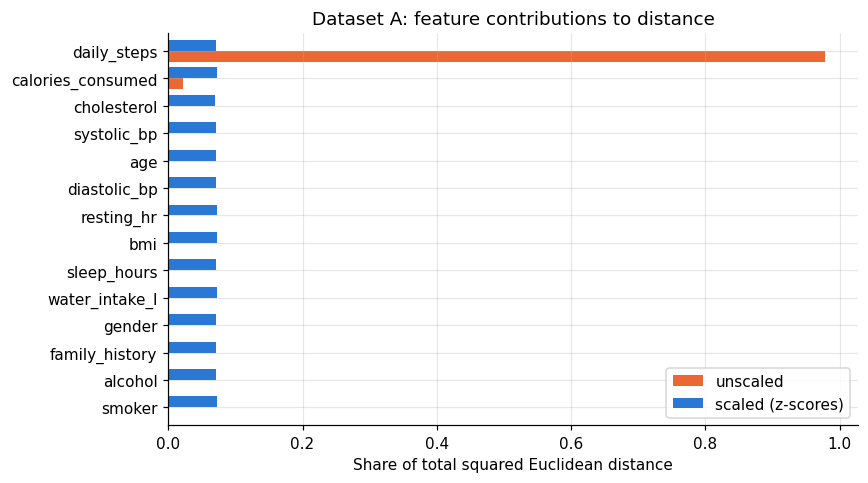

,unscaled,scaled (z-scores)
daily_steps,0.978,0.071
calories_consumed,0.022,0.072
cholesterol,0.000,0.070


In [10]:
rng = np.random.default_rng(SEED)
i, j = rng.integers(0, len(life_X), (2, 5000))
def share(M):
    sq = (M[i] - M[j]) ** 2
    return pd.Series(sq.sum(0) / sq.sum(), index=life_X.columns)
contrib = pd.DataFrame({'unscaled': share(life_X.values),
                        'scaled (z-scores)': share(StandardScaler().fit_transform(life_X))})
ax = contrib.sort_values('unscaled').plot.barh(figsize=(8, 4.5), color=['#eb6834', '#2a78d6'], width=0.8)
ax.set_xlabel('Share of total squared Euclidean distance'); ax.set_title('Dataset A: feature contributions to distance')
plt.tight_layout(); plt.show()
contrib.sort_values('unscaled', ascending=False).head(3).round(3)

Unscaled, `daily_steps` and `calories_consumed` account for nearly all of the distance, so "nearest neighbor" just means "similar step count." After converting to z-scores, every feature contributes roughly equally. Now the effect on BRFSS model quality, for both metrics:

In [11]:
rows = []
for metric in ['euclidean', 'manhattan']:
    for scale in [False, True]:
        rows.append({'metric': metric, 'scaled': scale, 'CV AUC (k=51)': cv_auc(knn(51, metric, scale=scale))[0]})
scal = pd.DataFrame(rows).pivot(index='metric', columns='scaled', values='CV AUC (k=51)')
scal.columns = ['unscaled', 'scaled']; scal['gain from scaling'] = scal['scaled'] - scal['unscaled']
scal.round(4)

,unscaled,scaled,gain from scaling
metric,,,
euclidean,0.7769,0.7942,0.0173
manhattan,0.7898,0.7990,0.0092


In [12]:
print('Unscaled BRFSS feature standard deviations (largest):')
print(X_train.std().sort_values(ascending=False).head(5).round(2).to_string())

Unscaled BRFSS feature standard deviations (largest):
PhysHlth    8.70
MentHlth    7.42
BMI         6.49
Age         3.05
Income      2.07


Without scaling, BMI (range 12–98) and the two 0–30 day counts swamp the binary flags. Scaling raises AUC for both metrics, and Euclidean gains more because squaring exaggerates the scale differences. All remaining models in this notebook are scaled inside a `Pipeline`, so the scaler is fit only on each training fold and no test-fold information leaks in.

Scaling does **not** remove outliers. A z-score is a linear transformation, so it keeps each value's position relative to the others. An extreme value stays extreme:

In [13]:
Z = pd.DataFrame(StandardScaler().fit_transform(X_train), columns=X_train.columns)
Z.abs().max().sort_values(ascending=False).head(6).round(1).to_frame('largest |z| after scaling')

,largest |z| after scaling
BMI,10.7
CholCheck,5.1
Stroke,4.9
AnyHealthcare,4.4
HvyAlcoholConsump,4.1
Education,4.1


Rare binary answers become especially extreme. For example, only about 4% of respondents had no cholesterol check, so the "0" answer for `CholCheck` sits about 5 standard deviations from the mean after scaling. This is one reason Manhattan, which does not square these gaps, performs better here.

## 5. Minkowski distance: tuning *p*
Minkowski distance generalizes both metrics: $d_p(x,z)=\left(\sum_j |x_j-z_j|^p\right)^{1/p}$. With $p=1$ it is Manhattan, and with $p=2$ it is Euclidean. Larger *p* lets the largest single difference dominate more. Smaller *p* (including $p<1$, which is no longer a true metric but can still be used for ranking neighbors) spreads the weight more evenly across features. Treating *p* as a hyperparameter:

In [14]:
ps = [0.25, 0.5, 0.75, 1, 1.5, 2, 3, 5]
t0 = time.time()
mink = pd.DataFrame([{'p': p, 'CV AUC': cv_auc(knn(51, 'minkowski', p=p))[0]} for p in ps]).set_index('p')
print(f'{time.time()-t0:.0f}s')
mink.round(4).T

/Users/komalmisra/micromamba/lib/python3.9/site-packages/sklearn/neighbors/_base.py:668: UserWarning: Mind that for 0 < p < 1, Minkowski metrics are not distance metrics. Continuing the execution with `algorithm='brute'`.
  warnings.warn(
/Users/komalmisra/micromamba/lib/python3.9/site-packages/sklearn/neighbors/_base.py:668: UserWarning: Mind that for 0 < p < 1, Minkowski metrics are not distance metrics. Continuing the execution with `algorithm='brute'`.
  warnings.warn(
/Users/komalmisra/micromamba/lib/python3.9/site-packages/sklearn/neighbors/_base.py:668: UserWarning: Mind that for 0 < p < 1, Minkowski metrics are not distance metrics. Continuing the execution with `algorithm='brute'`.
  warnings.warn(
/Users/komalmisra/micromamba/lib/python3.9/site-packages/sklearn/neighbors/_base.py:668: UserWarning: Mind that for 0 < p < 1, Minkowski metrics are not distance metrics. Continuing the execution with `algorithm='brute'`.
  warnings.warn(
/Users/komalmisra/micromamba/lib/python3.9/s

41s


p,0.25,0.50,0.75,1.00,1.50,2.00,3.00,5.00
CV AUC,0.7906,0.7957,0.7978,0.799,0.7981,0.7942,0.7871,0.7796


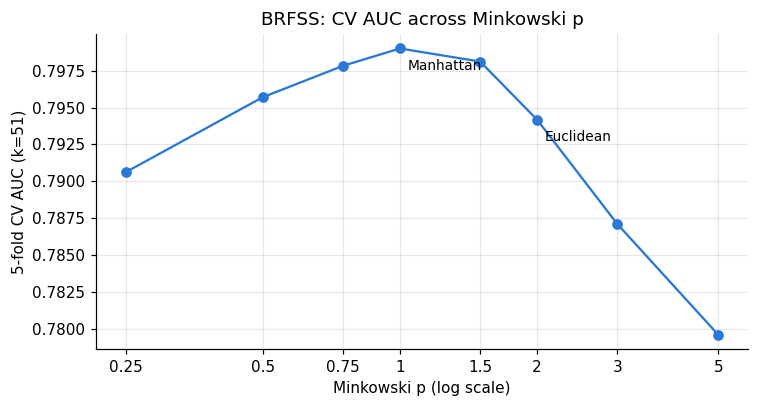

In [15]:
ax = mink['CV AUC'].plot(marker='o', color='#2a78d6', figsize=(7, 3.8), logx=True)
ax.xaxis.set_minor_locator(plt.NullLocator()); ax.set_xticks(ps); ax.set_xticklabels([str(p) for p in ps]); ax.set_xlabel('Minkowski p (log scale)'); ax.set_ylabel('5-fold CV AUC (k=51)')
for p, lab in [(1, 'Manhattan'), (2, 'Euclidean')]:
    ax.annotate(lab, (p, mink.loc[p, 'CV AUC']), textcoords='offset points', xytext=(5, -14), fontsize=9)
ax.set_title('BRFSS: CV AUC across Minkowski p'); plt.tight_layout(); plt.show()

AUC peaks at $p=1$ (Manhattan). Going below 1 does not help (AUC drops slightly, to 0.791 at $p=0.25$), and AUC declines steadily as *p* grows above 1. As *p* gets very large, the sum is dominated by its largest term, so Minkowski distance approaches the **Chebyshev** distance: the single largest feature difference.

In [16]:
x, z = np.array([0.0, 0.0, 0.0]), np.array([3.0, 2.0, 1.0])
for p in [1, 2, 5, 20, 100]:
    print(f'p={p:>3}: {(np.abs(x - z) ** p).sum() ** (1 / p):.4f}')
print('max |difference| =', np.abs(x - z).max())

p=  1: 6.0000
p=  2: 3.7417
p=  5: 3.0774
p= 20: 3.0000
p=100: 3.0000
max |difference| = 3.0


In [17]:
cheb = [cv_auc(knn(k, 'chebyshev'))[0] for k in ks]
results['chebyshev'] = cheb
pd.Series(cheb, index=pd.Index(ks, name='k'), name='Chebyshev CV AUC').round(4).to_frame().T

k,5,11,25,51,101,151
Chebyshev CV AUC,0.6917,0.7347,0.7579,0.7614,0.7572,0.7536


Chebyshev is clearly the weakest metric. It judges two respondents only by the one question they disagree on most and ignores the other 20, which is the opposite of what a broad survey profile needs.

## 6. Cosine distance
Cosine distance is $1-\cos\theta$, where $\theta$ is the angle between two vectors. It ignores vector length and compares only direction. In text, a document with word counts (2 eggs, 1 bacon) and one with (4 eggs, 2 bacon) point the same way, so their cosine distance is 0 even though their Euclidean distance is not:

In [18]:
from sklearn.metrics.pairwise import cosine_distances, euclidean_distances
docs = np.array([[2, 1], [4, 2], [1, 3]])   # counts of [egg, bacon]
pd.DataFrame({'cosine distance to doc 1': cosine_distances(docs)[0].round(3),
              'Euclidean distance to doc 1': euclidean_distances(docs)[0].round(3)},
             index=['doc 1 (2 egg, 1 bacon)', 'doc 2 (4 egg, 2 bacon)', 'doc 3 (1 egg, 3 bacon)'])

,cosine distance to doc 1,Euclidean distance to doc 1
"doc 1 (2 egg, 1 bacon)",0.000,0.000
"doc 2 (4 egg, 2 bacon)",0.000,2.236
"doc 3 (1 egg, 3 bacon)",0.293,2.236


For BRFSS, the features are standardized, so each vector records how far above or below average a respondent is on each question. Cosine distance then compares the *pattern* of a respondent's answers (which features are above average, and in what proportion) and ignores how extreme they are overall. Someone mildly above average on blood pressure, BMI and age points in the same direction as someone far above average on all three.

In [19]:
results['cosine'] = [cv_auc(knn(k, 'cosine'))[0] for k in ks]
pd.Series(results['cosine'], index=pd.Index(ks, name='k'), name='Cosine CV AUC').round(4).to_frame().T

k,5,11,25,51,101,151
Cosine CV AUC,0.7044,0.7551,0.7808,0.7953,0.798,0.7981


Cosine performs about as well as Euclidean but below Manhattan. Ignoring magnitude costs a little here, because *how far* someone is from average (for example, very poor vs. slightly below-average general health) carries real information about diabetes risk. Cosine is a natural fit when the overall scale of a vector is irrelevant, such as document length in text, and less so for clinical survey data, where severity matters.

## 7. Choosing *k* and checking for overfitting

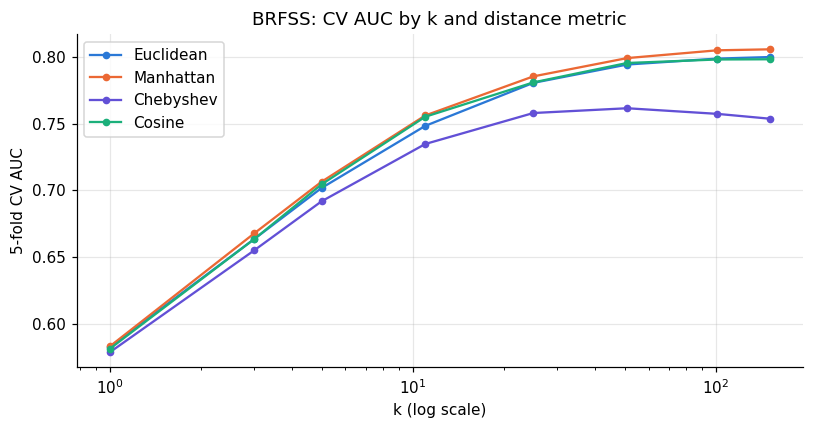

,euclidean,manhattan,chebyshev,cosine
k,,,,
1,0.5825,0.5830,0.5786,0.5812
3,0.6635,0.6677,0.6550,0.6635
5,0.7017,0.7063,0.6917,0.7044
11,0.7482,0.7560,0.7347,0.7551
25,0.7804,0.7853,0.7579,0.7808
51,0.7942,0.7990,0.7614,0.7953
101,0.7986,0.8048,0.7572,0.7980
151,0.7998,0.8056,0.7536,0.7981


In [20]:
ks_full = [1, 3, 5, 11, 25, 51, 101, 151]
for m in ['euclidean', 'manhattan', 'cosine', 'chebyshev']:
    have = dict(zip(ks, results[m]))
    results[m] = [have.get(k, None) or cv_auc(knn(k, m))[0] for k in ks_full]

fig, ax = plt.subplots(figsize=(7.5, 4))
for m, v in results.items():
    ax.plot(ks_full, v, marker='o', ms=4, color=COLORS[m], label=m.capitalize())
ax.set_xscale('log'); ax.set_xlabel('k (log scale)'); ax.set_ylabel('5-fold CV AUC')
ax.set_title('BRFSS: CV AUC by k and distance metric'); ax.legend(); plt.tight_layout(); plt.show()
summary = pd.DataFrame(results, index=pd.Index(ks_full, name='k')).round(4)
summary

To check overfitting, I compare AUC on the data the model was fit to (training AUC) with cross-validated AUC. A large gap means the model is memorizing rather than generalizing.

In [21]:
gap = []
for k in [1, 5, 51, 151]:
    m = knn(k, 'manhattan').fit(X_cv, y_cv)
    tr = roc_auc_score(y_cv, m.predict_proba(X_cv)[:, 1])
    gap.append({'k': k, 'train AUC': tr, 'CV AUC': summary.loc[k, 'manhattan'], 'gap': tr - summary.loc[k, 'manhattan']})
pd.DataFrame(gap).set_index('k').round(3)

,train AUC,CV AUC,gap
k,,,
1,0.999,0.583,0.416
5,0.899,0.706,0.192
51,0.827,0.799,0.028
151,0.817,0.806,0.012


At $k=1$, each training point is its own nearest neighbor, so training AUC is nearly perfect while CV AUC is barely above chance. That is pure memorization (training AUC is not exactly 1.0 because BRFSS contains duplicate rows with conflicting labels). The gap shrinks quickly as *k* grows, because each prediction then averages over many respondents. CV AUC rises up to about $k=101$–$151$ and then flattens. The best setting is **Manhattan with k = 151**, at the edge of the grid, but the gain from 101 to 151 is tiny. Diabetes risk is a broad tendency shared by many similar profiles, not something a few close matches pin down.

Distance weighting (closer neighbors get more say) is another way to set the size of a neighborhood:

In [22]:
pd.DataFrame({'uniform': [cv_auc(knn(51, 'manhattan'))[0]],
              'distance-weighted': [cv_auc(knn(51, 'manhattan', weights='distance'))[0]]}, index=['CV AUC (k=51)']).round(4)

,uniform,distance-weighted
CV AUC (k=51),0.799,0.7973


Distance weighting makes essentially no difference here, so I keep uniform weights.

## 8. Final model on the test set
KNN has no `class_weight` option, so with 15.8% prevalence it rarely reaches the default 0.5 cutoff (at least 76 of 151 neighbors diabetic). I choose the cutoff that maximizes F1 using **out-of-fold** predictions on the CV slice, never the test set, then refit on all 40,000 training rows and evaluate once.

In [23]:
best_k, best_metric = 151, 'manhattan'
final = knn(best_k, best_metric)
oof = cross_val_predict(final, X_cv, y_cv, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_cv, oof)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
cut = thr[np.argmax(f1[:-1])]
print(f'F1-optimal cutoff from out-of-fold predictions: {cut:.3f}')

final.fit(X_train, y_train)
t0 = time.time(); proba = final.predict_proba(X_test)[:, 1]; print(f'Prediction time for 10,000 rows: {time.time()-t0:.1f}s')

def report(pred):
    return {'accuracy': accuracy_score(y_test, pred), 'precision': precision_score(y_test, pred, zero_division=0),
            'recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred)}
test = pd.DataFrame({'cutoff 0.5': report(proba >= 0.5), f'cutoff {cut:.2f}': report(proba >= cut),
                     'always predict 0': report(np.zeros_like(proba))}).T.round(3)
print(f'Test AUC: {roc_auc_score(y_test, proba):.3f}')
test

F1-optimal cutoff from out-of-fold predictions: 0.232
Prediction time for 10,000 rows: 0.8s
Test AUC: 0.803


,accuracy,precision,recall,F1
cutoff 0.5,0.844,0.567,0.051,0.093
cutoff 0.23,0.780,0.378,0.611,0.467
always predict 0,0.842,0.000,0.000,0.000


At the default cutoff, the model's accuracy looks fine, but it catches almost no diabetic respondents, which makes it no better than always predicting "no diabetes." With the tuned cutoff it identifies most diabetic respondents, at the cost of some false positives and lower accuracy. For a screening program, that is the right trade, since an extra screening costs much less than a missed case. Test AUC is close to the CV estimate, which confirms the choice of *k* and metric was not overfit to the CV folds.

## 9. Dataset A: Health & Lifestyle
Earlier weeks found no recoverable signal in Dataset A. KNN gives an independent check: if similar people (in steps, sleep, vitals and so on) do not share outcomes, neighbors carry no information.

In [24]:
yA_risk, yA_bmi = life['disease_risk'], life['bmi']
XA = life_X.drop(columns=['bmi'])
XA_tr, XA_te, ra_tr, ra_te, ba_tr, ba_te = train_test_split(XA, yA_risk, yA_bmi, test_size=0.2,
                                                            stratify=yA_risk, random_state=SEED)
XA_tr, ra_tr, ba_tr = XA_tr.iloc[:30_000], ra_tr.iloc[:30_000], ba_tr.iloc[:30_000]

rowsA = []
for metric in ['euclidean', 'manhattan', 'cosine']:
    algo = 'brute' if metric == 'cosine' else 'auto'
    clf = make_pipeline(StandardScaler(), KNeighborsClassifier(51, metric=metric, algorithm=algo, n_jobs=-1)).fit(XA_tr, ra_tr)
    reg = make_pipeline(StandardScaler(), KNeighborsRegressor(51, metric=metric, algorithm=algo, n_jobs=-1)).fit(XA_tr, ba_tr)
    rowsA.append({'metric': metric, 'disease_risk AUC': roc_auc_score(ra_te, clf.predict_proba(XA_te)[:, 1]),
                  'BMI RMSE': mean_squared_error(ba_te, reg.predict(XA_te)) ** 0.5})
resA = pd.DataFrame(rowsA).set_index('metric')
resA['BMI RMSE (predict the mean)'] = np.sqrt(((ba_te - ba_tr.mean()) ** 2).mean())
resA.round(4)

,disease_risk AUC,BMI RMSE,BMI RMSE (predict the mean)
metric,,,
euclidean,0.5036,6.4131,6.3428
manhattan,0.5116,6.4112,6.3428
cosine,0.5016,6.4170,6.3428


Every metric gives AUC between 0.50 and 0.51 (chance) for `disease_risk`, and BMI error is slightly *worse* than simply predicting the average BMI for everyone. Changing the distance metric cannot help when no metric makes "similar people" share outcomes. This is consistent with the earlier finding that Dataset A's columns behave as if they were generated independently.

## 10. Summary
| Question | Finding (BRFSS unless noted) |
|---|---|
| Euclidean vs. Manhattan | Manhattan is better at every k. With mostly binary survey features, a single extreme answer should not dominate the distance. |
| Feature scaling | Essential. Unscaled, BMI and day-count features dominate (in Dataset A, step count alone does). Euclidean benefits more from scaling than Manhattan. Scaling keeps outliers in place, it does not remove them. |
| Minkowski p | p = 1 (Manhattan) is best; smaller p is slightly worse and larger p steadily worse. Very large p approaches Chebyshev, the weakest metric. |
| Cosine | Similar to Euclidean, below Manhattan. Ignoring magnitude discards severity information that matters clinically. |
| Choosing k | k = 1 memorizes the training data (train–CV gap above 0.4). AUC rises until about k = 100–150 and then levels off. |
| Final model | Manhattan, k = 151. Needs a tuned cutoff (well below 0.5) to catch diabetic respondents, because KNN cannot reweight classes. |
| Dataset A | No metric finds signal: AUC 0.50–0.51, and BMI RMSE is slightly worse than predicting the mean. |

KNN is easy to explain to a client ("people like you had these outcomes"), but it is slower to score than a fitted model and needs scaling, a good metric, a large k and a tuned cutoff to work well on imbalanced health data.

**Sources:** scikit-learn User Guide, *Nearest Neighbors* (https://scikit-learn.org/stable/modules/neighbors.html); Hastie, Tibshirani & Friedman (2009), *The Elements of Statistical Learning*, Ch. 13; James et al. (2021), *An Introduction to Statistical Learning*, Ch. 2 and 4.